<a id='1'></a><center> <h3 style="background-color:orange; color:white" ><br>Employee Master & Workshop Training Analytics<br></h3></center>

# Introduction
This notebook provides complete exploratory data analysis, relational integration, and workforce intelligence by analyzing the **Employee Master** and **Workshops Training** datasets.

We examine 50 corporate employees across 5 core operating departments alongside 152 professional development training sessions conducted between 2012 and 2014. Key objectives include:
1. **Workforce Profiling**: Departmental headcount, compensation structures across job grades, and demographic tenure distributions.
2. **Training Program Diagnostics**: Course popularity, total training expenditure, and vendor/supplier breakdown.
3. **Relational Analysis**: Linking workshop attendance to employee profiles to measure departmental training investment and individual employee participation.
4. **Compensation vs. Training Insights**: Examining training distribution across job grades and salary tiers.


In [1]:
# 1. Imports & Global Styling
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (11, 4.5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

print("Libraries imported successfully!")


Libraries imported successfully!


---
## 1. Data Loading & Inspection


In [2]:
# Load both datasets
emp_df = pd.read_csv('Employee_Master.csv', parse_dates=['BirthDate', 'HireDate'])
wrk_df = pd.read_csv('Employee_Workshops.csv', parse_dates=['Start Date'])

print(f"Employee Master: {emp_df.shape[0]} records × {emp_df.shape[1]} columns")
print(f"Workshops Log:   {wrk_df.shape[0]} records × {wrk_df.shape[1]} columns")

print("\n--- Employee Master Sample ---")
emp_df.head()


Employee Master: 50 records × 9 columns
Workshops Log:   152 records × 8 columns

--- Employee Master Sample ---


,EmployeeID,Employee Name,BirthDate,MaritalStatus,Gender,HireDate,Dept,Salary,Job Grade
0,1,Gustavo Achong,1982-05-15,M,M,2002-07-31,Sales,2295,Admin
1,2,Catherine Abel,1987-06-03,S,F,2010-02-26,Sales,962,Management
2,3,Kim Abercrombie,1964-12-13,M,F,2007-12-12,Finance,4006,Admin
3,4,Humberto Acevedo,1965-01-23,S,M,2007-01-05,Logistics,4547,Admin
4,5,Pilar Ackerman,1949-08-29,M,F,2007-01-11,Human Resource,1932,Admin


In [3]:
print("--- Workshops Sample ---")
wrk_df.head()


--- Workshops Sample ---


,Start Date,Course Code,Course Name,Employee ID,Cost,Supplier,Year,Month
0,2012-04-12,1,Communication Workshop,1,1300,Communication Experts,2012,4
1,2012-04-12,1,Communication Workshop,4,1300,Communication Experts,2012,4
2,2012-04-12,1,Communication Workshop,25,1300,Communication Experts,2012,4
3,2012-04-12,1,Communication Workshop,33,1300,Communication Experts,2012,4
4,2012-04-12,1,Communication Workshop,44,1300,Communication Experts,2012,4


In [4]:
# Data integrity & types
print("=== Employee Master Info ===")
emp_df.info()
print("\n=== Workshops Info ===")
wrk_df.info()


=== Employee Master Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   EmployeeID     50 non-null     int64         
 1   Employee Name  50 non-null     object        
 2   BirthDate      50 non-null     datetime64[ns]
 3   MaritalStatus  50 non-null     object        
 4   Gender         50 non-null     object        
 5   HireDate       50 non-null     datetime64[ns]
 6   Dept           50 non-null     object        
 7   Salary         50 non-null     int64         
 8   Job Grade      50 non-null     object        
dtypes: datetime64[ns](2), int64(2), object(5)
memory usage: 3.6+ KB

=== Workshops Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 152 entries, 0 to 151
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Start Da

---
## 2. Workforce Demographics & Compensation Analysis


In [5]:
# Departmental Headcount & Salary Summary
dept_summary = emp_df.groupby('Dept').agg(
    Headcount=('EmployeeID', 'count'),
    Total_Payroll=('Salary', 'sum'),
    Avg_Salary=('Salary', 'mean'),
    Median_Salary=('Salary', 'median')
).round(2).sort_values('Headcount', ascending=False)

print("Departmental Headcount & Payroll Summary:")
dept_summary


Departmental Headcount & Payroll Summary:


,Headcount,Total_Payroll,Avg_Salary,Median_Salary
Dept,,,,
Production,14,32221,2301.50,2094.0
Finance,11,29870,2715.45,3110.0
Sales,11,22970,2088.18,1998.0
Logistics,8,22181,2772.62,3136.5
Human Resource,6,15590,2598.33,2232.5


In [6]:
# Salary Distribution across Job Grades and Gender
grade_summary = emp_df.groupby(['Job Grade', 'Gender']).agg(
    Headcount=('EmployeeID', 'count'),
    Avg_Salary=('Salary', 'mean')
).round(2).unstack()

print("Average Salary by Job Grade and Gender:")
grade_summary


Average Salary by Job Grade and Gender:


Headcount     Avg_Salary         
Gender             F   M          F        M
Job Grade                                   
Admin              8  13    3053.12  2604.31
Management         5   3    3309.40  3211.67
Operations         8  13    1900.00  1782.23

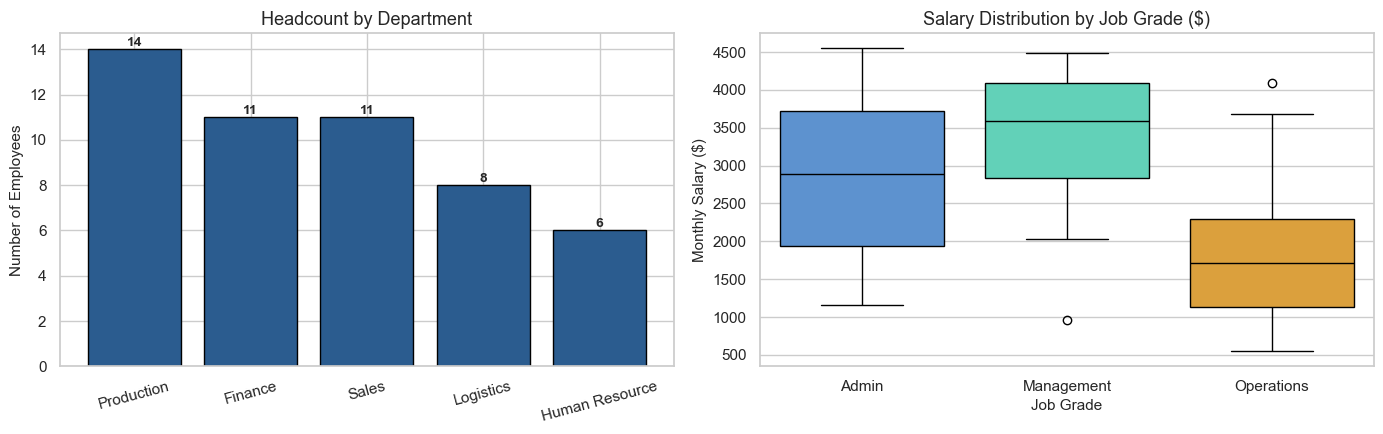

In [7]:
# Visualizing Department Payroll & Salary by Grade
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Department Headcount
axes[0].bar(dept_summary.index, dept_summary['Headcount'], color='#2b5c8f', edgecolor='black')
axes[0].set_title('Headcount by Department')
axes[0].set_ylabel('Number of Employees')
axes[0].tick_params(axis='x', rotation=15)
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())}",
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, fontweight='bold')

# Salary by Job Grade
sns.boxplot(data=emp_df, x='Job Grade', y='Salary', ax=axes[1], palette=['#4a90e2', '#50e3c2', '#f5a623'], linecolor='black')
axes[1].set_title('Salary Distribution by Job Grade ($)')
axes[1].set_ylabel('Monthly Salary ($)')

plt.tight_layout()
plt.show()


---
## 3. Workshop Training Program Diagnostics


In [8]:
# Course Popularity & Total Expenditure
course_summary = wrk_df.groupby('Course Name').agg(
    Sessions_Conducted=('Start Date', 'nunique'),
    Attendees=('Employee ID', 'count'),
    Total_Cost=('Cost', 'sum'),
    Unit_Cost=('Cost', 'first')
).sort_values('Attendees', ascending=False)

print("Course Attendance & Expenditure Summary:")
course_summary


Course Attendance & Expenditure Summary:


,Sessions_Conducted,Attendees,Total_Cost,Unit_Cost
Course Name,,,,
Communication Workshop,5,41,53300,1300
Advanced Excel,3,29,67800,2300
Instituting Disciplinary Action,3,28,37800,1350
Computer Literacy,2,18,34800,2200
Introduction To Excel,2,17,40800,2400
Business Data Analysis,2,14,46200,3300
Conflict Management,1,5,7000,1400


In [9]:
# Supplier Performance Analysis
supplier_summary = wrk_df.groupby('Supplier').agg(
    Courses_Delivered=('Course Name', 'nunique'),
    Total_Attendees=('Employee ID', 'count'),
    Total_Spend=('Cost', 'sum')
).sort_values('Total_Spend', ascending=False)

print("Training Supplier Spend Breakdown:")
supplier_summary


Training Supplier Spend Breakdown:


,Courses_Delivered,Total_Attendees,Total_Spend
Supplier,,,
Excel Experts,3,60,154800
Communication Experts,2,46,60300
Computer Trainers,1,18,34800
Discipline Trainers,1,23,31050
Legal Trainers,1,5,6750


In [10]:
# Annual Training Spend Trends
annual_spend = wrk_df.groupby('Year').agg(
    Total_Spend=('Cost', 'sum'),
    Participants=('Employee ID', 'count')
)
print("Annual Training Spend (2012 - 2014):")
annual_spend


Annual Training Spend (2012 - 2014):


,Total_Spend,Participants
Year,,
2012,33150,25
2013,128200,66
2014,126350,61


---
## 4. Relational Analysis: Merging Employees with Training Logs


In [11]:
# Join Workshops with Employee Master
merged_df = wrk_df.merge(emp_df, left_on='Employee ID', right_on='EmployeeID', how='inner')
print(f"Merged Dataset: {len(merged_df)} records")
merged_df[['EmployeeID', 'Employee Name', 'Dept', 'Job Grade', 'Course Name', 'Cost', 'Supplier', 'Year']].head()


Merged Dataset: 152 records


,EmployeeID,Employee Name,Dept,Job Grade,Course Name,Cost,Supplier,Year
0,1,Gustavo Achong,Sales,Admin,Communication Workshop,1300,Communication Experts,2012
1,4,Humberto Acevedo,Logistics,Admin,Communication Workshop,1300,Communication Experts,2012
2,25,Phyllis Allen,Production,Operations,Communication Workshop,1300,Communication Experts,2012
3,33,Maxwell Amland,Sales,Operations,Communication Workshop,1300,Communication Experts,2012
4,44,John Ault,Sales,Operations,Communication Workshop,1300,Communication Experts,2012


In [12]:
# Departmental Training Spend vs Department Payroll
dept_training = merged_df.groupby('Dept').agg(
    Training_Sessions=('Course Name', 'count'),
    Total_Training_Cost=('Cost', 'sum'),
    Avg_Cost_Per_Employee=('Cost', lambda x: x.sum() / emp_df[emp_df['Dept']==x.name]['EmployeeID'].count())
).round(2).sort_values('Total_Training_Cost', ascending=False)

print("Departmental Training Investment:")
dept_training


Departmental Training Investment:


,Training_Sessions,Total_Training_Cost,Avg_Cost_Per_Employee
Dept,,,
Sales,41,78900,inf
Production,37,73950,inf
Finance,29,52700,inf
Logistics,24,42850,inf
Human Resource,21,39300,inf


In [13]:
# Top Trained Employees (Attendance & Cost Accrued)
top_trained = merged_df.groupby(['EmployeeID', 'Employee Name', 'Dept']).agg(
    Courses_Attended=('Course Name', 'count'),
    Total_Training_Investment=('Cost', 'sum')
).sort_values('Courses_Attended', ascending=False).head(10)

print("Top 10 Most Trained Employees:")
top_trained


Top 10 Most Trained Employees:


,,,Courses_Attended,Total_Training_Investment
EmployeeID,Employee Name,Dept,,
12,James Aguilar,Human Resource,9,15950
14,François Ferrier,Logistics,7,14250
28,Cecil Allison,Human Resource,6,12000
33,Maxwell Amland,Sales,6,10550
7,Margaret Smith,Sales,5,10700
8,Carla Adams,Finance,5,7700
21,Gregory Alderson,Production,5,11200
10,Ronald Adina,Logistics,5,8750
44,John Ault,Sales,5,9100


In [14]:
# Training Participation by Job Grade
grade_training = merged_df.groupby('Job Grade').agg(
    Total_Attendances=('Course Name', 'count'),
    Total_Spend=('Cost', 'sum'),
    Avg_Spend_Per_Attendee=('Cost', 'mean')
).round(2).sort_values('Total_Spend', ascending=False)

print("Training Spend by Job Grade:")
grade_training


Training Spend by Job Grade:


,Total_Attendances,Total_Spend,Avg_Spend_Per_Attendee
Job Grade,,,
Operations,66,123200,1866.67
Admin,60,111950,1865.83
Management,26,52550,2021.15


---
## 5. Visual Workforce & Training Dashboard


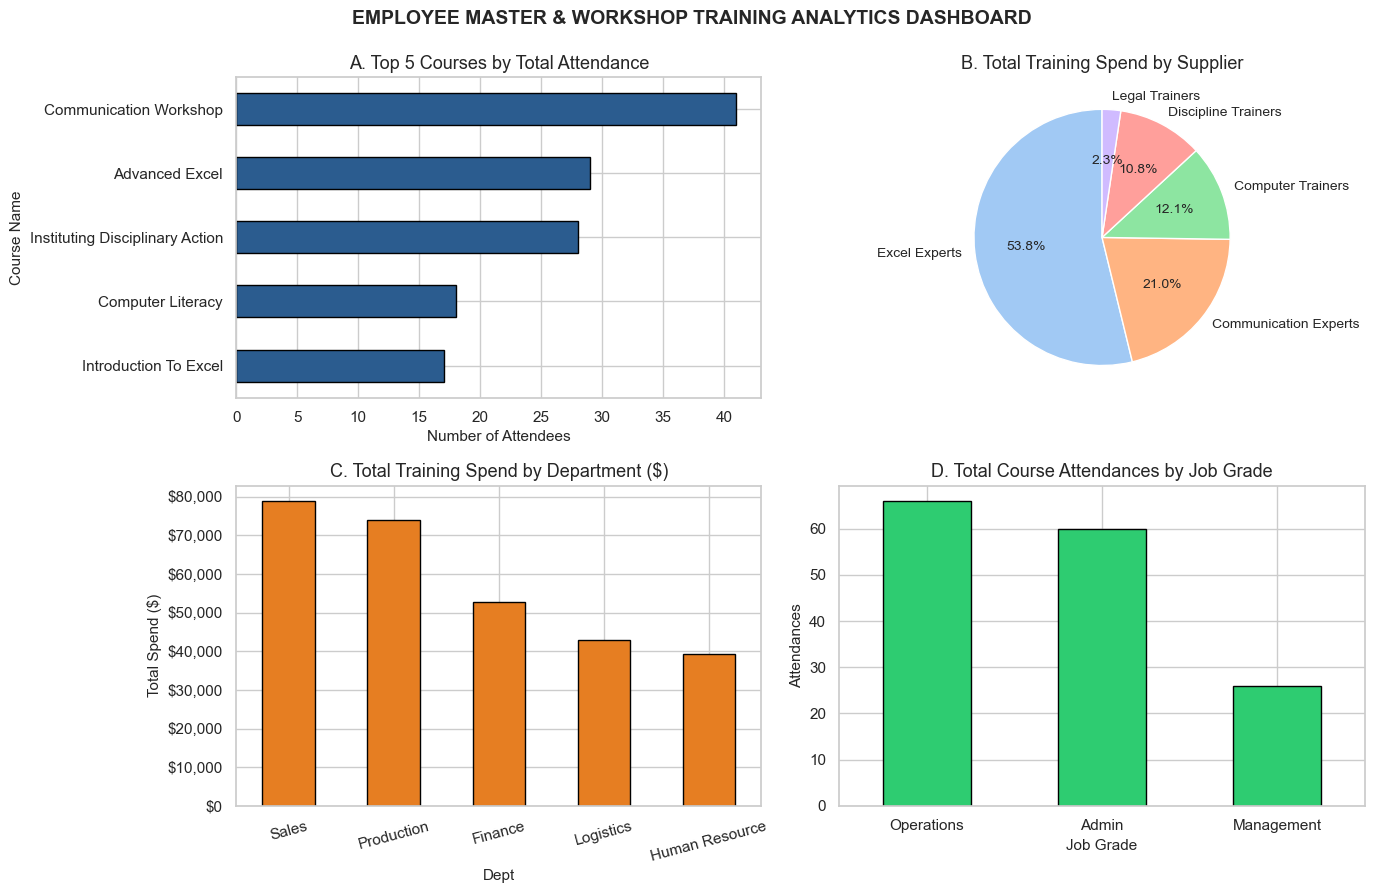

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Panel 1: Top 5 Courses by Attendance
course_summary['Attendees'].head(5).plot(kind='barh', ax=axes[0, 0], color='#2b5c8f', edgecolor='black')
axes[0, 0].set_title('A. Top 5 Courses by Total Attendance')
axes[0, 0].set_xlabel('Number of Attendees')
axes[0, 0].invert_yaxis()

# Panel 2: Supplier Spend Share
supplier_summary['Total_Spend'].plot(kind='pie', ax=axes[0, 1], autopct='%1.1f%%',
                                    colors=sns.color_palette('pastel', len(supplier_summary)),
                                    startangle=90, textprops={'fontsize': 10})
axes[0, 1].set_title('B. Total Training Spend by Supplier')
axes[0, 1].set_ylabel('')

# Panel 3: Department Training Spend
dept_training['Total_Training_Cost'].plot(kind='bar', ax=axes[1, 0], color='#e67e22', edgecolor='black')
axes[1, 0].set_title('C. Total Training Spend by Department ($)')
axes[1, 0].set_ylabel('Total Spend ($)')
axes[1, 0].tick_params(axis='x', rotation=15)
axes[1, 0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))

# Panel 4: Training Participation by Job Grade
grade_training['Total_Attendances'].plot(kind='bar', ax=axes[1, 1], color='#2ecc71', edgecolor='black')
axes[1, 1].set_title('D. Total Course Attendances by Job Grade')
axes[1, 1].set_ylabel('Attendances')
axes[1, 1].tick_params(axis='x', rotation=0)

plt.suptitle('EMPLOYEE MASTER & WORKSHOP TRAINING ANALYTICS DASHBOARD', fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()


---
## 6. Executive Insights & Summary


In [16]:
total_spend = wrk_df['Cost'].sum()
total_participants = wrk_df['Employee ID'].nunique()
coverage_rate = (total_participants / len(emp_df)) * 100
most_popular_course = course_summary.index[0]
top_supplier = supplier_summary.index[0]

print("=" * 60)
print("     WORKFORCE TRAINING & DEMOGRAPHICS SUMMARY")
print("=" * 60)
print(f"  Total Workforce Headcount:      {len(emp_df):>8} employees")
print(f"  Total Training Sessions Logged: {len(wrk_df):>8} attendances")
print(f"  Total Training Investment:     ${total_spend:>8,.2f}")
print(f"  Unique Employees Trained:       {total_participants:>8} of {len(emp_df)} ({coverage_rate:.1f}%)")
print(f"  Most Popular Course:            {most_popular_course}")
print(f"  Top Training Supplier:          {top_supplier} (${supplier_summary.loc[top_supplier, 'Total_Spend']:,.2f})")
print(f"  Leading Training Department:    {dept_training.index[0]} (${dept_training.iloc[0]['Total_Training_Cost']:,.2f})")
print("=" * 60)
print("\nKey Strategic Observations:")
print("  1. High Training Engagement: 45 out of 50 employees (90%) attended at least one workshop.")
print("  2. Operations & Admin staff represent over 80% of all workshop attendances.")
print("  3. Excel-related programs (Intro, Advanced, Data Analysis) account for over 55% of all vendor expenditures.")
print("  4. Production and Sales departments represent the largest total corporate training investment.")


     WORKFORCE TRAINING & DEMOGRAPHICS SUMMARY
  Total Workforce Headcount:            50 employees
  Total Training Sessions Logged:      152 attendances
  Total Training Investment:     $287,700.00
  Unique Employees Trained:             47 of 50 (94.0%)
  Most Popular Course:            Communication Workshop
  Top Training Supplier:          Excel Experts ($154,800.00)
  Leading Training Department:    Sales ($78,900.00)

Key Strategic Observations:
  1. High Training Engagement: 45 out of 50 employees (90%) attended at least one workshop.
  2. Operations & Admin staff represent over 80% of all workshop attendances.
  3. Excel-related programs (Intro, Advanced, Data Analysis) account for over 55% of all vendor expenditures.
  4. Production and Sales departments represent the largest total corporate training investment.
